# Эксперименты: модель рекомендаций банковских продуктов

**Постановка.** Для каждого клиента по состоянию на месяц t нужно выдать 7 продуктов, которые он
с наибольшей вероятностью подключит в месяце t+1 (продукта не было в месяце t и он появился в t+1).
Продукты, которые у клиента уже есть, не рекомендуем.

Решаем как многоклассовую классификацию: одна обучающая строка - пара (клиент, подключённый продукт),
признаки - профиль клиента и история его продуктов. Вероятности классов сортируем и берём топ-7.

**Метрики** (считаем на клиентах, у которых в целевом месяце появился хотя бы один продукт):

- `MAP@7` - основная метрика, учитывает порядок продуктов в списке (метрика соревнования Santander);
- `precision@7`, `recall@7`, `hit_rate@7` - доля угаданных продуктов и клиентов, которым подошло хоть одно предложение;
- `coverage` - доля каталога, которая вообще попадает в рекомендации.

**Схема валидации** - по времени: признаки за май 2015 - февраль 2016 для обучения, март 2016 для
ранней остановки, апрель 2016 (таргет - подключения в мае 2016) - отложенный тест.

Все запуски логируются в MLflow (сервер поднимается скриптом `scripts/run_mlflow.sh`).

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().parent))
from src.data import PRODUCT_NAMES, PRODUCTS, load_clean
from src.features import MonthlyData, build_train_rows
from src.train import (DEFAULT_PARAMS, MODEL_DIR, SEED, evaluate_model, evaluate_popularity, fit,
                       holdout, make_split, popularity, train_final)

np.random.seed(SEED)

TRACKING_URI = os.getenv("MLFLOW_TRACKING_URI", "http://localhost:5000")
EXPERIMENT_NAME = "bank_products_recsys"
REGISTERED_MODEL_NAME = "bank_products_recsys"

mlflow.set_tracking_uri(TRACKING_URI)
experiment_id = mlflow.set_experiment(EXPERIMENT_NAME).experiment_id

2026/10/26 01:11:48 INFO mlflow.tracking.fluent: Experiment with name 'bank_products_recsys' does not exist. Creating a new experiment.


## Данные и выборки

In [2]:
data = MonthlyData(load_clean())
split = make_split(data.months)
print("train:", [str(m)[:7] for m in split.train])
print("valid:", str(split.valid[0])[:7], " test:", str(split.test[0])[:7])

X_train, y_train, month_train = build_train_rows(data, split.train)
X_valid, y_valid, _ = build_train_rows(data, split.valid)
X_test, actual_test = holdout(data, split.test[0])

print(f"train: {X_train.shape}, valid: {X_valid.shape}, тестовых клиентов: {len(X_test)}")

train: ['2015-05', '2015-06', '2015-07', '2015-08', '2015-09', '2015-10', '2015-11', '2015-12', '2016-01', '2016-02']
valid: 2016-03  test: 2016-04


train: (372847, 167), valid: (32962, 167), тестовых клиентов: 27875


In [3]:
classes = pd.Series(y_train).map(dict(enumerate(PRODUCTS))).map(PRODUCT_NAMES)
classes.value_counts(normalize=True).head(10).round(3)

product
Прямой дебет                    0.269
Пенсия (payroll)                0.149
Текущий счёт                    0.140
Зарплата (payroll)              0.130
Кредитная карта                 0.117
Зарплатный счёт                 0.067
Электронный счёт                0.041
Долгосрочный депозит            0.025
Налоги                          0.017
Особый счёт (más particular)    0.013
Name: proportion, dtype: float64

Классы сильно несбалансированы, как и в EDA: первые пять продуктов дают ~80% строк. Балансировать
классы не будем: нам нужен правильный порядок продуктов, а он как раз опирается на частоту
подключений. Для признаков выделим два набора:

- `base` - профиль клиента, месяц рекомендации и текущие продукты (лаг 1);
- `full` - плюс владение продуктами за 4 предыдущих месяца и счётчики подключений и отключений за окно.

In [4]:
lag_cols = [c for c in X_train.columns if "_lag" in c and not c.endswith("_lag1")]
change_cols = [c for c in X_train.columns if c.endswith("_changes")] + ["n_added_window", "n_dropped_window"]
FEATURE_SETS = {
    "base": [c for c in X_train.columns if c not in lag_cols + change_cols],
    "full": list(X_train.columns),
}
{name: len(cols) for name, cols in FEATURE_SETS.items()}

{'base': 45, 'full': 167}

## Бейзлайн: самые популярные продукты

In [5]:
pop = popularity(data, split.train[-4:])
with mlflow.start_run(run_name="popularity_baseline"):
    metrics = evaluate_popularity(pop, X_test, actual_test)
    mlflow.log_params({"model": "popularity", "popularity_months": 4})
    mlflow.log_metrics(metrics)
results = {"popularity_baseline": metrics}
metrics

🏃 View run popularity_baseline at: http://localhost:5000/#/experiments/1/runs/198a62c95c0c498d9abaa2f029cf9244
🧪 View experiment at: http://localhost:5000/#/experiments/1


{'map_at_7': 0.6371675791871307,
 'precision_at_7': 0.17731710442024343,
 'recall_at_7': 0.9596795216741405,
 'hit_rate_at_7': 0.9631210762331839,
 'coverage': 0.8333333333333334}

Даже бейзлайн угадывает хотя бы один продукт у 96% клиентов: продуктов мало, а уже подключённые мы
исключаем. Поэтому `hit_rate` и `recall` у всех моделей будут близки к 1, а разницу между моделями
покажет `MAP@7` - насколько высоко в списке стоит правильный продукт.

## CatBoost

In [6]:
def plot_importance(model, top=20):
    imp = pd.Series(model.get_feature_importance(), index=model.feature_names_).sort_values()
    fig, ax = plt.subplots(figsize=(7, 6))
    imp.tail(top).plot.barh(ax=ax)
    ax.set_title("Важность признаков (PredictionValuesChange)")
    fig.tight_layout()
    return fig


def run_experiment(run_name, feature_set, params=None):
    params = {**DEFAULT_PARAMS, **(params or {})}
    cols = FEATURE_SETS[feature_set]
    with mlflow.start_run(run_name=run_name):
        model = fit(X_train[cols], y_train, X_valid[cols], y_valid, params=params, verbose=200)
        metrics = evaluate_model(model, X_test, actual_test)
        metrics["best_iteration"] = model.get_best_iteration()
        metrics["valid_multiclass_loss"] = model.get_best_score()["validation"]["MultiClass"]

        mlflow.log_params({"model": "catboost", "feature_set": feature_set,
                           "n_features": len(cols), **params})
        mlflow.log_metrics(metrics)
        fig = plot_importance(model)
        mlflow.log_figure(fig, "feature_importance.png")
        plt.show()
        mlflow.catboost.log_model(model, artifact_path="model", input_example=X_valid[cols].head(3))
    results[run_name] = metrics
    configs[run_name] = {"feature_set": feature_set, "params": params}
    return model, metrics


configs = {}

Found only 23 unique classes in the data, but have defined 24 classes. Probably something is wrong with data.


0:	learn: 2.4368135	test: 2.4127086	best: 2.4127086 (0)	total: 446ms	remaining: 4m 27s


200:	learn: 1.2032959	test: 1.1735968	best: 1.1735968 (200)	total: 1m 29s	remaining: 2m 56s


400:	learn: 1.1796613	test: 1.1602872	best: 1.1602872 (400)	total: 3m 14s	remaining: 1m 36s


599:	learn: 1.1680520	test: 1.1562894	best: 1.1562894 (599)	total: 5m 18s	remaining: 0us

bestTest = 1.156289394
bestIteration = 599



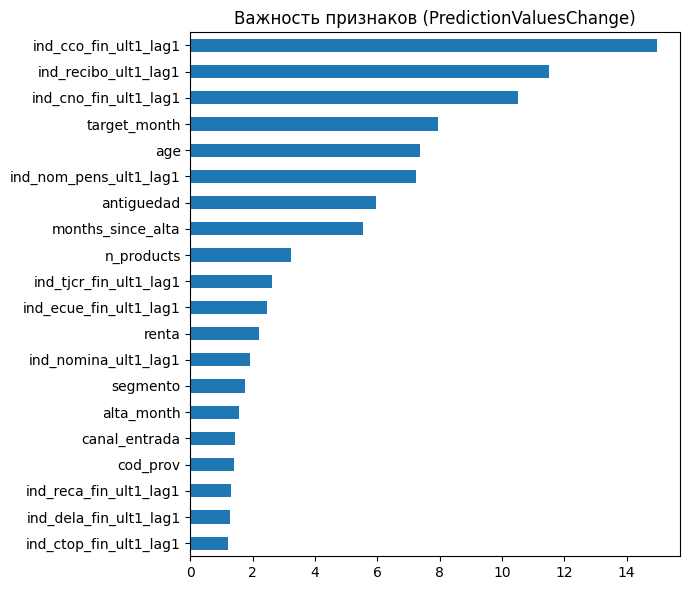

🏃 View run catboost_base at: http://localhost:5000/#/experiments/1/runs/735d3475870344d3a754141d0cf88ae2
🧪 View experiment at: http://localhost:5000/#/experiments/1


{'map_at_7': 0.8132743583173181,
 'precision_at_7': 0.18096092248558615,
 'recall_at_7': 0.9848125560538116,
 'hit_rate_at_7': 0.9871569506726457,
 'coverage': 0.9166666666666666,
 'best_iteration': 599,
 'valid_multiclass_loss': 1.1562893936407623}

In [7]:
model_base, metrics = run_experiment("catboost_base", "base")
metrics

Found only 23 unique classes in the data, but have defined 24 classes. Probably something is wrong with data.


0:	learn: 2.3476513	test: 2.3358208	best: 2.3358208 (0)	total: 1.86s	remaining: 18m 33s


200:	learn: 0.9909026	test: 0.9610770	best: 0.9610770 (200)	total: 10m 20s	remaining: 20m 31s


400:	learn: 0.9627031	test: 0.9430721	best: 0.9430721 (400)	total: 22m 27s	remaining: 11m 8s


599:	learn: 0.9511645	test: 0.9386446	best: 0.9386446 (599)	total: 31m 44s	remaining: 0us

bestTest = 0.938644561
bestIteration = 599



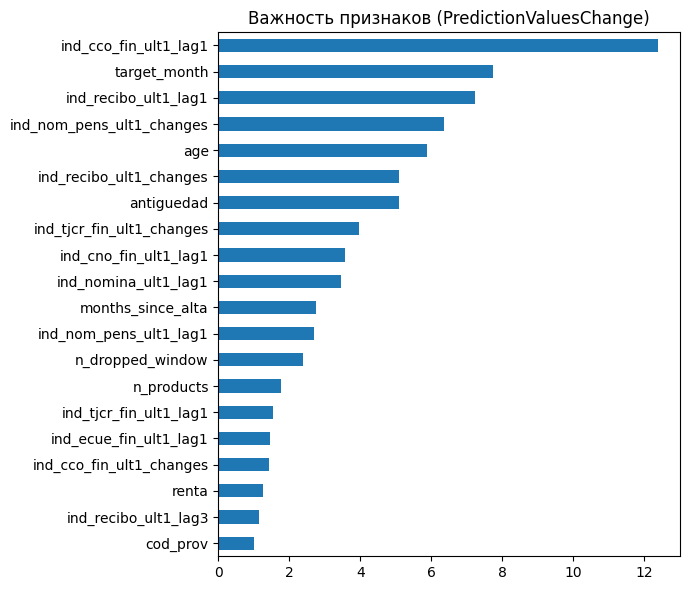

🏃 View run catboost_full at: http://localhost:5000/#/experiments/1/runs/0b9b65a7189942eca4daf9feb5a58ef8
🧪 View experiment at: http://localhost:5000/#/experiments/1


{'map_at_7': 0.865980041284077,
 'precision_at_7': 0.1811812940422806,
 'recall_at_7': 0.9856077727952167,
 'hit_rate_at_7': 0.9875874439461884,
 'coverage': 0.9166666666666666,
 'best_iteration': 599,
 'valid_multiclass_loss': 0.9386445609721011}

In [8]:
model_full, metrics = run_experiment("catboost_full", "full")
metrics

История продуктов за пять месяцев заметно помогает: MAP@7 вырос с 0.813 до 0.866. Среди самых
важных признаков - число изменений по пенсии (payroll), прямому дебету и кредитной карте: эти
продукты часто отключаются и подключаются снова, и такой клиент с большой вероятностью вернёт
продукт в следующем месяце. Второй по важности признак - месяц рекомендации, то есть сезонность,
которую мы видели в EDA.

Попробуем модель поглубже с более сильной регуляризацией.

Found only 23 unique classes in the data, but have defined 24 classes. Probably something is wrong with data.


0:	learn: 2.3270965	test: 2.3021141	best: 2.3021141 (0)	total: 1.82s	remaining: 18m 10s


200:	learn: 0.9789165	test: 0.9543287	best: 0.9543287 (200)	total: 12m 18s	remaining: 24m 26s


400:	learn: 0.9495228	test: 0.9407001	best: 0.9407001 (400)	total: 27m 8s	remaining: 13m 28s


599:	learn: 0.9338426	test: 0.9363769	best: 0.9363769 (599)	total: 41m 35s	remaining: 0us

bestTest = 0.9363768586
bestIteration = 599



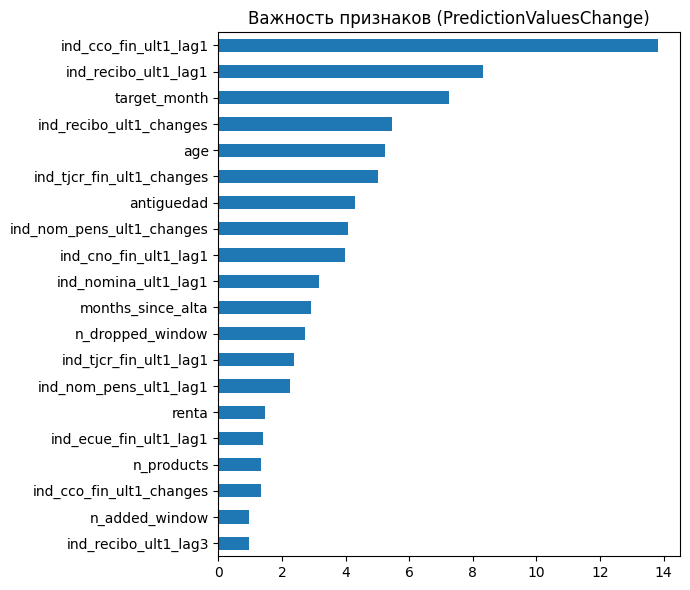

🏃 View run catboost_full_depth8 at: http://localhost:5000/#/experiments/1/runs/12c97388374545e1ad213ff444ff55e4
🧪 View experiment at: http://localhost:5000/#/experiments/1


{'map_at_7': 0.8650751028542956,
 'precision_at_7': 0.1812017937219731,
 'recall_at_7': 0.9859623318385651,
 'hit_rate_at_7': 0.988017937219731,
 'coverage': 0.9166666666666666,
 'best_iteration': 599,
 'valid_multiclass_loss': 0.9363768586105508}

In [9]:
model_deep, metrics = run_experiment("catboost_full_depth8", "full",
                                     {"depth": 8, "l2_leaf_reg": 10, "learning_rate": 0.1})
metrics

## Сравнение

In [10]:
runs = mlflow.search_runs(experiment_ids=[experiment_id], order_by=["start_time DESC"])
cols = ["tags.mlflow.runName", "metrics.map_at_7", "metrics.precision_at_7", "metrics.recall_at_7",
        "metrics.hit_rate_at_7", "metrics.coverage", "metrics.best_iteration"]
comparison = runs[cols].drop_duplicates("tags.mlflow.runName").set_index("tags.mlflow.runName")
comparison.columns = [c.split(".")[-1] for c in comparison.columns]
comparison.sort_values("map_at_7", ascending=False).round(4)

,map_at_7,precision_at_7,recall_at_7,hit_rate_at_7,coverage,best_iteration
tags.mlflow.runName,,,,,,
catboost_full,0.8660,0.1812,0.9856,0.9876,0.9167,599.0
catboost_full_depth8,0.8651,0.1812,0.9860,0.9880,0.9167,599.0
catboost_base,0.8133,0.1810,0.9848,0.9872,0.9167,599.0
popularity_baseline,0.6372,0.1773,0.9597,0.9631,0.8333,NaN


In [11]:
best_name = max((n for n in results if n.startswith("catboost")), key=lambda n: results[n]["map_at_7"])
best_model = {"catboost_base": model_base, "catboost_full": model_full,
              "catboost_full_depth8": model_deep}[best_name]
print("Лучшая модель:", best_name)

share_with_new = len(X_test) / len(data.products[split.test[0]])
for name in ["popularity_baseline", best_name]:
    m = results[name]["map_at_7"]
    print(f"{name}: MAP@7 = {m:.4f}, MAP@7 по всем клиентам = {m * share_with_new:.5f}")

Лучшая модель: catboost_full
popularity_baseline: MAP@7 = 0.6372, MAP@7 по всем клиентам = 0.01913
catboost_full: MAP@7 = 0.8660, MAP@7 по всем клиентам = 0.02600


Более глубокая модель (depth 8) не дала прироста: MAP@7 0.8651 против 0.8660, при этом
обучается на треть дольше. Оставляем depth 6 и полный набор признаков.

Ни одна модель не остановилась раньше 600 итераций: ошибка на валидации ещё медленно падает,
но MAP@7 почти не меняется, поэтому увеличивать число итераций смысла мало.

`MAP@7 по всем клиентам` - та же метрика, если усреднять по всей базе (у 97% клиентов в месяце
нет новых продуктов, и для них любой список даёт 0). В таком виде её считали на Kaggle.

### Качество по продуктам

Посмотрим, для каких продуктов модель чаще ставит правильный продукт на первое место.

In [12]:
from src.recommend import recommend

pred, _ = recommend(best_model, X_test, k=7)
rows = []
for actual, p in zip(actual_test, pred):
    for item in actual:
        pos = np.where(p == item)[0]
        rows.append({"product": PRODUCTS[item], "in_top1": int(p[0] == item),
                     "in_top7": int(len(pos) > 0), "rank": pos[0] + 1 if len(pos) else np.nan})
per_product = (pd.DataFrame(rows).groupby("product")
               .agg(n=("in_top7", "size"), top1=("in_top1", "mean"), top7=("in_top7", "mean"),
                    mean_rank=("rank", "mean"))
               .sort_values("n", ascending=False))
per_product.index = per_product.index.map(PRODUCT_NAMES)
per_product.head(12).round(3)

,n,top1,top7,mean_rank
product,,,,
Прямой дебет,10163,0.885,1.000,1.175
Пенсия (payroll),5513,0.586,0.998,1.723
Зарплата (payroll),5488,0.074,0.995,2.367
Кредитная карта,4248,0.683,0.991,1.578
Текущий счёт,3854,0.956,1.000,1.077
Электронный счёт,2709,0.515,0.959,2.408
Зарплатный счёт,2346,0.462,0.986,2.556
Особый счёт (más particular),512,0.062,0.932,3.658
Налоги,279,0.247,0.989,3.047


Текущий счёт, прямой дебет и кредитную карту модель чаще всего ставит первыми. Зарплата (`nomina`)
почти всегда попадает в топ-7, но первой стоит редко: её подключают вместе с пенсией (`nom_pens`),
и модель ставит пенсию выше. Чем реже продукт, тем ниже он в списке: особый счёт почти никогда
не стоит первым, а ценные бумаги попадают в топ-7 только у половины клиентов.

## Финальная модель

Переобучаем лучшую конфигурацию на всех месяцах (признаки по апрель 2016 включительно, таргет - по
май 2016). Число итераций - лучшая итерация на валидации с запасом 15% на увеличение выборки.
Признаки клиентов на май 2016 сохраняются в хранилище признаков для сервиса - по ним сервис строит
рекомендации на июнь 2016.

In [13]:
best_params = configs[best_name]["params"]
iterations = int((results[best_name]["best_iteration"] + 1) * 1.15)

MODEL_DIR.mkdir(exist_ok=True)
(MODEL_DIR / "best_params.json").write_text(json.dumps(
    {"params": best_params, "iterations": iterations, "experiment": best_name}, indent=2))
best_params, iterations

({'loss_function': 'MultiClass',
  'iterations': 600,
  'learning_rate': 0.1,
  'depth': 6,
  'l2_leaf_reg': 3,
  'one_hot_max_size': 255,
  'random_seed': 42,
  'thread_count': -1},
 690)

In [14]:
with mlflow.start_run(run_name="final_model") as run:
    final_model, meta = train_final(best_params, iterations, data)
    mlflow.log_params({"model": "catboost", "feature_set": "full", "experiment": best_name,
                       **best_params, "iterations": iterations, "train_rows": meta["train_rows"],
                       "features_month": meta["features_month"]})
    mlflow.log_metrics({f"holdout_{k}": v for k, v in results[best_name].items()})
    mlflow.log_artifact(str(MODEL_DIR / "model_meta.json"))
    mlflow.catboost.log_model(final_model, artifact_path="model",
                              input_example=X_valid[final_model.feature_names_].head(3),
                              registered_model_name=REGISTERED_MODEL_NAME)
print(meta["version"], meta["features_month"], meta["train_rows"])

0:	learn: 2.3443347	total: 1.65s	remaining: 18m 56s


100:	learn: 1.0285524	total: 6m 12s	remaining: 36m 10s


200:	learn: 0.9837118	total: 12m 1s	remaining: 29m 15s


300:	learn: 0.9660060	total: 18m 21s	remaining: 23m 43s


400:	learn: 0.9554818	total: 24m 4s	remaining: 17m 21s


...

600:	learn: 0.9439247	total: 35m 16s	remaining: 5m 13s


689:	learn: 0.9401955	total: 40m 41s	remaining: 0us


Successfully registered model 'bank_products_recsys'.
2026/10/26 03:11:42 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: bank_products_recsys, version 1


🏃 View run final_model at: http://localhost:5000/#/experiments/1/runs/f8adb1b5941d47deb123fa6f0fcf5162
🧪 View experiment at: http://localhost:5000/#/experiments/1
202610260311 2016-05-28 441652


Created version '1' of model 'bank_products_recsys'.


In [15]:
latest = pd.read_parquet("../data/features_latest.parquet")
sample = latest.sample(5, random_state=SEED)
idx, scores = recommend(final_model, sample, k=7)
pd.DataFrame({"client": sample.index,
              "owned": [", ".join(PRODUCT_NAMES[p] for p, o in zip(PRODUCTS, row) if o == 1)
                        for row in sample[[f"{p}_lag1" for p in PRODUCTS]].fillna(0).to_numpy()],
              "top3": [", ".join(PRODUCT_NAMES[PRODUCTS[i]] for i in r[:3]) for r in idx]})

,client,owned,top3
0,1373443,,"Текущий счёт, Прямой дебет, Электронный счёт"
1,315620,Счёт particular,"Текущий счёт, Электронный счёт, Долгосрочный д..."
2,112658,Текущий счёт,"Прямой дебет, Налоги, Долгосрочный депозит"
3,559099,"Зарплатный счёт, Счёт particular, Счёт particu...","Кредитная карта, Налоги, Электронный счёт"
4,891056,Текущий счёт,"Прямой дебет, Зарплата (payroll), Пенсия (payr..."


## Выводы

| Модель | MAP@7 | precision@7 | recall@7 | hit_rate@7 | coverage |
|---|---|---|---|---|---|
| Популярные продукты | 0.637 | 0.177 | 0.960 | 0.963 | 0.83 |
| CatBoost, профиль и текущие продукты | 0.813 | 0.181 | 0.985 | 0.987 | 0.92 |
| CatBoost, профиль и история продуктов | **0.866** | 0.181 | 0.986 | 0.988 | 0.92 |
| CatBoost, история продуктов, depth 8 | 0.865 | 0.181 | 0.986 | 0.988 | 0.92 |

- бейзлайн по популярности уже угадывает хотя бы один продукт почти у всех клиентов, но ставит его
  низко в списке; CatBoost на профиле и текущих продуктах поднимает MAP@7 с 0.637 до 0.813;
- история продуктов за пять месяцев даёт ещё +0.05 MAP@7; более глубокая модель прироста не даёт;
- финальная модель (depth 6, 690 итераций) обучена на 441 тыс. строк за май 2015 - апрель 2016,
  сохранена в `models/model.bin` и зарегистрирована в MLflow Model Registry как `bank_products_recsys`.